In [1]:
import pickle
from pathlib import Path

import numpy as np
import jax
import jax.numpy as jnp
import jax.scipy as jsp
import scipy
import matplotlib.pyplot as plt
import operator
from jax import config
from functools import partial
from matplotlib.lines import Line2D
config.update("jax_enable_x64", True)

import os

import polars as pl
import statistics

from matplotlib.colors import CenteredNorm
import scipy.stats as scis
# from scipy.stats import norm
from cmfa.emu_example import ordered_ilr_func, closure


In [2]:
RESULTS_DIR = Path("..") / "data" / "results" / "toy_example"
PLOT_DIR = Path("..") / "figures"

In [3]:
true_flux = np.load(RESULTS_DIR / "true_flux.npy")
true_id = np.load(RESULTS_DIR / "true_composition.npy")
print(f"True flux: {true_flux}")
print(f"True isotopologue distribution: {true_id}")


True flux: [100. 110.  50.  20.  20.  80.]
True isotopologue distribution: [6.34920635e-05 8.00761905e-01 1.98285714e-01 8.88888889e-04]


We start with analysis of the reference flux set from Antoniwitch 

In [4]:
intensity_msts = jnp.load(RESULTS_DIR / "intensity_measurements_reference.npy")
simulated_id = jnp.load(RESULTS_DIR / "id_simulated_reference.npy")

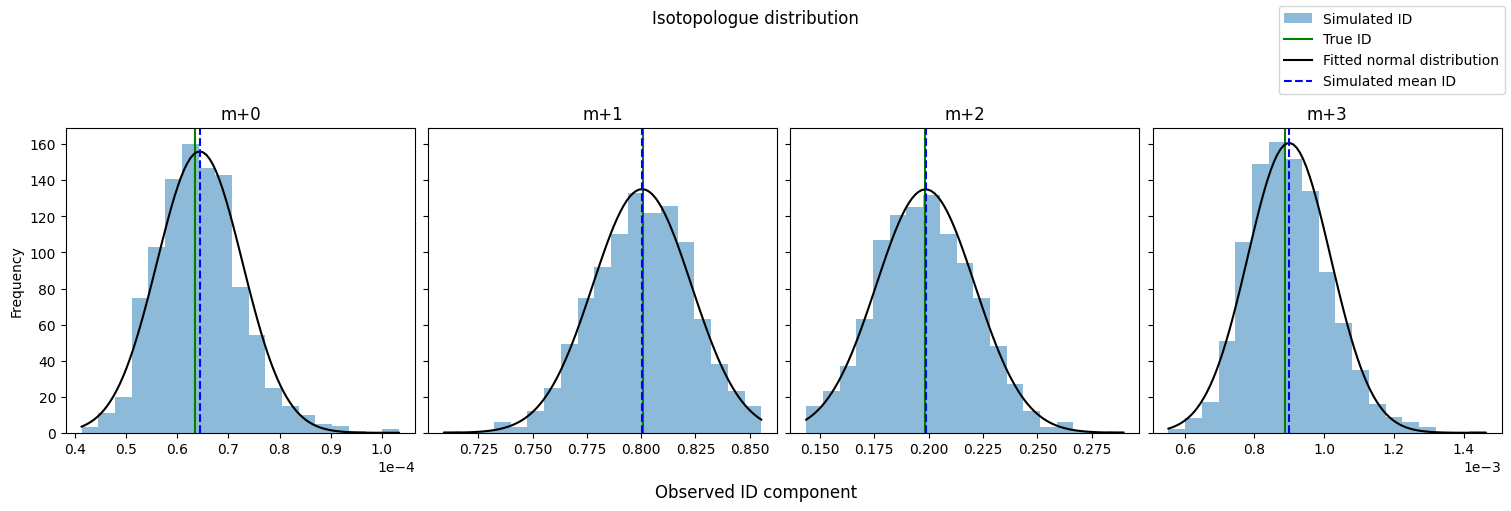

In [5]:
f, axes = plt.subplots(1, 4, figsize=[15, 5], sharey=True, layout='constrained')

for (i, ax) in enumerate(axes):
    simulated_id_i = simulated_id[:,i].flatten()
    xmin = np.min(simulated_id_i)
    xmax = np.max(simulated_id_i)
    bins = np.linspace(xmin, xmax, 20)
    bin_width = bins[1] - bins[0]
    h_trad = ax.hist(
        simulated_id_i, 
        bins=bins,
        alpha=0.5,
        label=f"Simulated ID",
    )
    ax.set(title=f"m+{i}")
    ax.axvline(true_id[i], label="True ID", color="green")
    mu, std = scis.norm.fit(simulated_id_i)
    x = np.linspace(xmin, xmax, 100)
    p = scis.norm.pdf(x, mu, std)
    scaled_p = p * len(simulated_id_i) * bin_width
    ax.plot(x, scaled_p, "k", label="Fitted normal distribution")
    ax.axvline(mu, label="Simulated mean ID", color="blue", linestyle="--")
    ax.ticklabel_format(scilimits=(-2,3))
    # ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");
h,l = ax.get_legend_handles_labels()
f.supxlabel("Observed ID component")
f.legend(labels=l, loc="outside upper right")
f.suptitle("Isotopologue distribution");
f.savefig(PLOT_DIR / "simulated_id_toy.png", bbox_inches="tight", dpi=200)


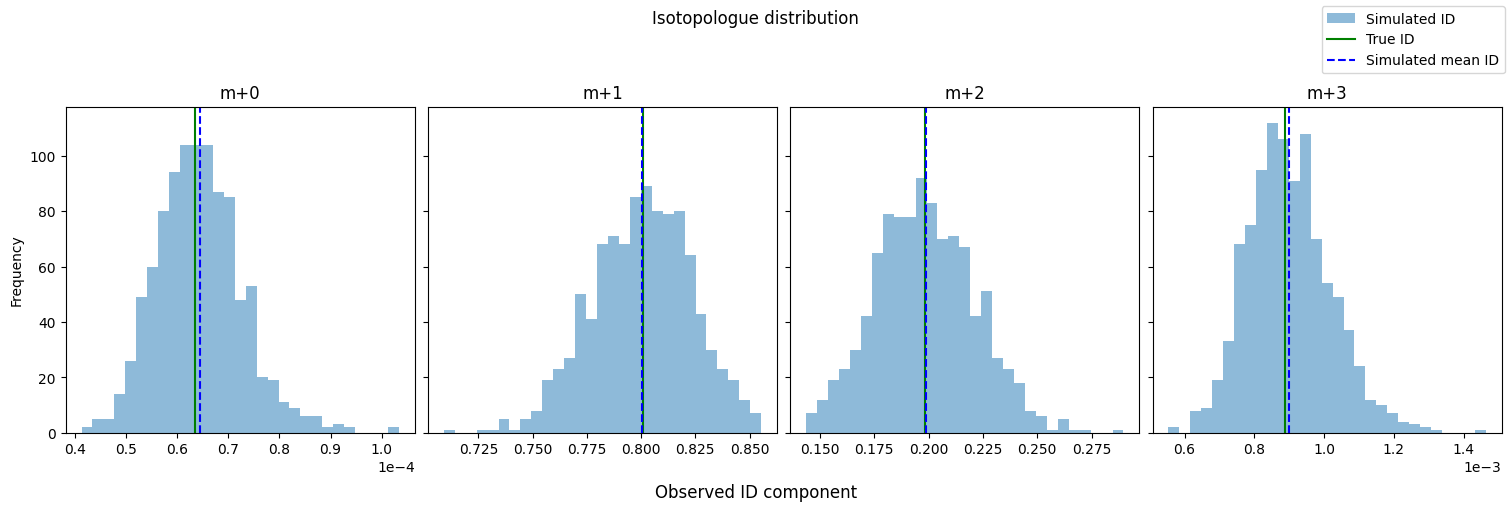

In [6]:
f, axes = plt.subplots(1, 4, figsize=[15, 5], sharey=True, layout='constrained')

for (i, ax) in enumerate(axes):
    simulated_id_i = simulated_id[:,i].flatten()
    xmin = np.min(simulated_id_i)
    xmax = np.max(simulated_id_i)
    bins = np.linspace(xmin, xmax, 30)
    bin_width = bins[1] - bins[0]
    h_trad = ax.hist(
        simulated_id_i, 
        bins=bins,
        alpha=0.5,
        label=f"Simulated ID",
    )
    ax.set(title=f"m+{i}")
    ax.axvline(true_id[i], label="True ID", color="green")
    mu, std = scis.norm.fit(simulated_id_i)
    x = np.linspace(xmin, xmax, 100)
    p = scis.norm.pdf(x, mu, std)
    scaled_p = p * len(simulated_id_i) * bin_width
    # ax.plot(x, scaled_p, "k", label="Fitted normal distribution")
    ax.axvline(mu, label="Simulated mean ID", color="blue", linestyle="--")
    ax.ticklabel_format(scilimits=(-2,3))
    # ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");
h,l = ax.get_legend_handles_labels()
f.supxlabel("Observed ID component")
f.legend(labels=l, loc="outside upper right")
f.suptitle("Isotopologue distribution");
f.savefig(PLOT_DIR / "simulated_id_toy.png", bbox_inches="tight", dpi=200)


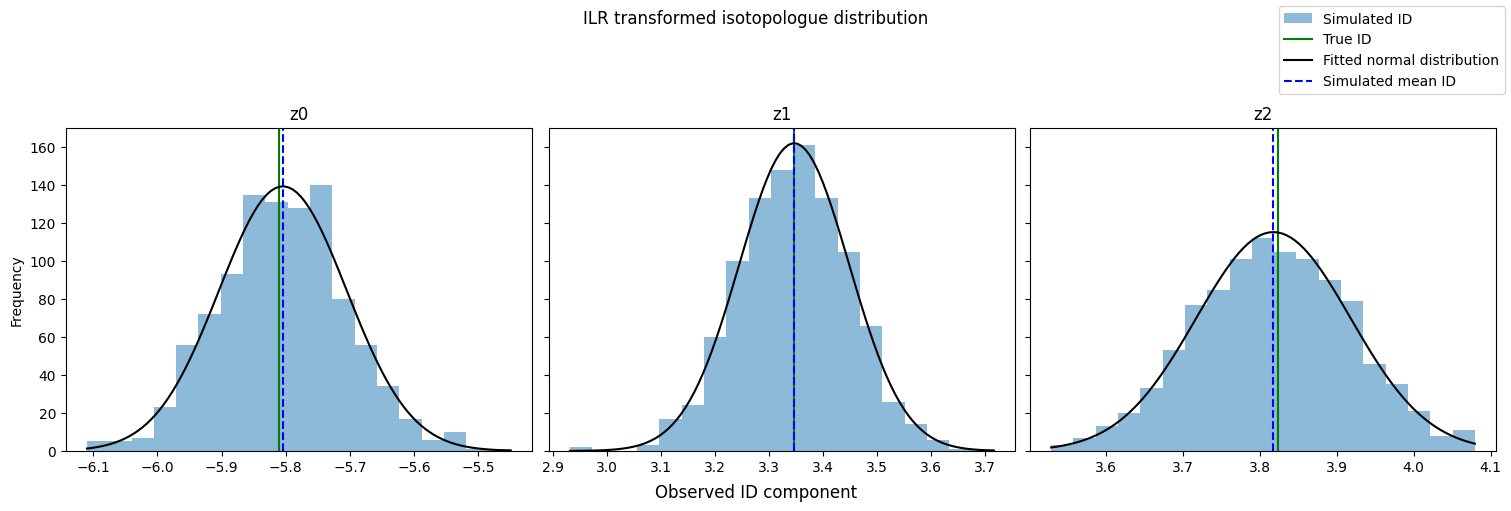

In [7]:
ilr_id_msts_true = ordered_ilr_func(simulated_id)
true_ilr_id = ordered_ilr_func(true_id)
f, axes = plt.subplots(1, 3, figsize=[15, 5], sharey=True, layout="constrained")

for (i, ax) in enumerate(axes):
    ilr_id_i = ilr_id_msts_true[:,i].flatten()
    xmin = np.min(ilr_id_i)
    xmax = np.max(ilr_id_i)
    bins = np.linspace(xmin, xmax, 20)
    bin_width = bins[1] - bins[0]
    h_trad = ax.hist(
        ilr_id_i, 
        bins=bins,
        alpha=0.5,
        label=f"Simulated ID" 
    )
    ax.set(title=f"z{i}")
    ax.axvline(true_ilr_id[i], label="True ID", color="green")
    mu, std = scis.norm.fit(ilr_id_i)
    x = np.linspace(xmin, xmax, 100)
    p = scis.norm.pdf(x, mu, std)
    scaled_p = p * len(ilr_id_i) * bin_width
    ax.plot(x, scaled_p, "k", label="Fitted normal distribution")
    ax.axvline(mu, label="Simulated mean ID", color="blue", linestyle="--")
    # ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");
h,l = ax.get_legend_handles_labels()
f.supxlabel("Observed ID component")
f.legend(labels=l, loc="outside upper right")
f.suptitle("ILR transformed isotopologue distribution");
f.savefig(PLOT_DIR / "simulated_ilr_toy.png", bbox_inches="tight", dpi=200)

In [8]:
with open(RESULTS_DIR / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_ref = pickle.load(f)
estimated_fluxes_ref["trad"].shape

(1000, 6)

In [9]:
with open(RESULTS_DIR / "estimated_ids_reference.pkl", "rb") as f:
    estimated_ids_ref = pickle.load(f)
estimated_ids_ref["trad"].shape

(1000, 4)

In [19]:
estimated_fluxes_ref["trad"][:, [1, 3]]

Array([[45.96402361, 13.17033856],
       [47.18023231, 11.2437486 ],
       [47.91777744, 14.15829478],
       ...,
       [47.57062776, 13.91878822],
       [47.88329096, 13.14611538],
       [83.13353557, 26.02400689]], dtype=float64)

In [10]:
resid_trad = (true_flux[None, [1, 3]] - estimated_fluxes_ref["trad"][:, [1, 3]])/true_flux[None, [1, 3]]
resid_clr = (true_flux[None, [1, 3]] - estimated_fluxes_ref["clr"][:, [1, 3]])/true_flux[None, [1, 3]]
resid_ilr = (true_flux[None, [1, 3]] - estimated_fluxes_ref["ilr"][:, [1, 3]])/true_flux[None, [1, 3]]

mse_trad = (resid_trad ** 2).mean(axis=(0))
mse_clr = (resid_clr ** 2).mean(axis=(0))
mse_ilr = (resid_ilr ** 2).mean(axis=(0))

mse_trad, mse_clr, mse_ilr

(Array([0.17083764, 0.06213587], dtype=float64),
 Array([0.01925045, 0.0072037 ], dtype=float64),
 Array([0.0192497 , 0.00720352], dtype=float64))

In [11]:
# nmse_trad = mse_trad/true_flux[None, [2, 4]]
# nmse_clr = mse_clr/true_flux[None, [2, 4]]
# nmse_ilr = mse_ilr/true_flux[None, [2, 4]]
# nmse_trad, nmse_clr, nmse_ilr

In [12]:
id_resid_trad = estimated_ids_ref["trad"] - true_id
id_resid_clr = estimated_ids_ref["clr"] - true_id
id_resid_ilr = estimated_ids_ref["ilr"] - true_id

id_mse_trad = (id_resid_trad ** 2).mean(axis=(0))
id_mse_clr = (id_resid_clr ** 2).mean(axis=(0))
id_mse_ilr = (id_resid_ilr ** 2).mean(axis=(0))

id_mse_trad, id_mse_clr, id_mse_ilr

(Array([6.04842035e-09, 5.18841463e-04, 5.12634891e-04, 2.23090015e-08],      dtype=float64),
 Array([6.09766516e-11, 5.02170408e-04, 4.99570895e-04, 7.66446229e-09],      dtype=float64),
 Array([6.09768779e-11, 5.02153115e-04, 4.99553619e-04, 7.66450699e-09],      dtype=float64))

In [13]:
# id_nmse_trad = id_mse_trad/true_id
# id_nmse_clr = id_mse_clr/true_id
# id_nmse_ilr = id_mse_ilr/true_id

# id_nmse_trad, id_nmse_clr, id_nmse_ilr

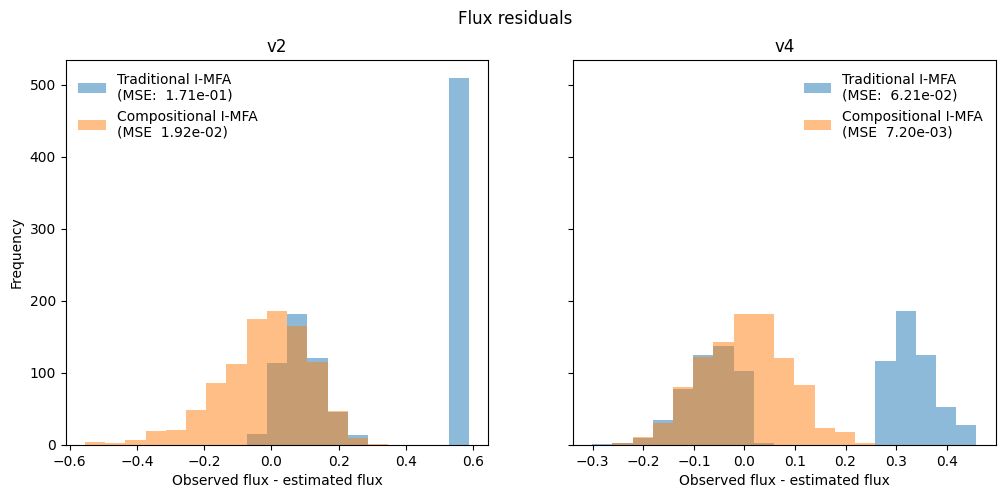

In [15]:
f, axes = plt.subplots(1, 2, figsize=[12, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_trad_i = resid_trad[:, i].flatten()
    resid_comp_i = resid_ilr[:, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 20)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {mse_trad[i]: .2e})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE {mse_ilr[i]: .2e})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{2+2*i}", xlabel="Observed flux - estimated flux")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");

f.suptitle("Flux residuals");
f.savefig(PLOT_DIR / "flux_residuals_toy_true.png", bbox_inches="tight", dpi=200)

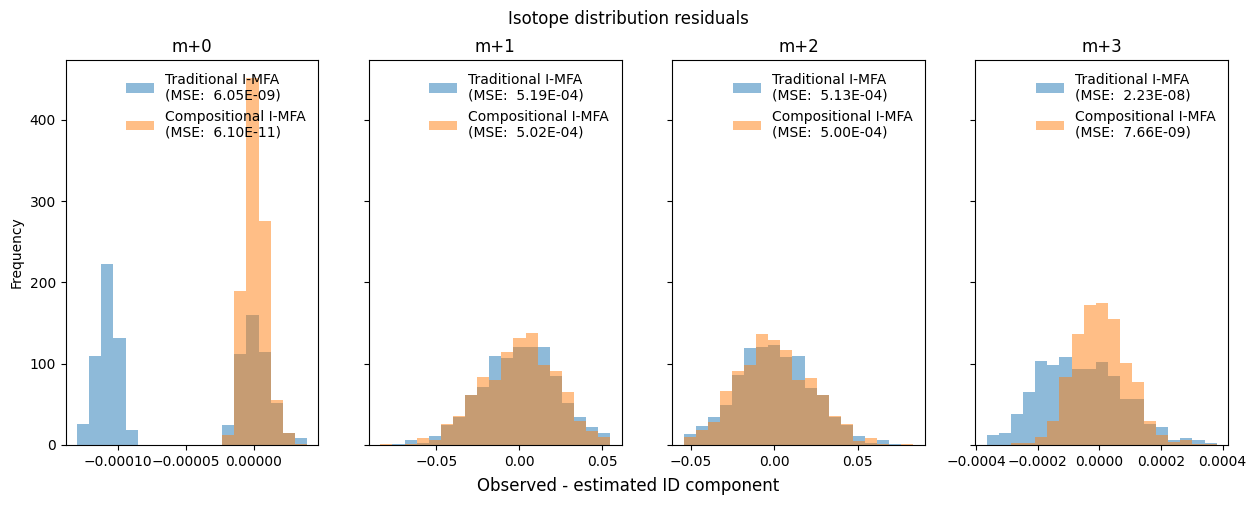

In [20]:
f, axes = plt.subplots(1, 4, figsize=[15, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_trad_i = id_resid_trad[:, i].flatten()
    resid_comp_i = id_resid_ilr[:, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 20)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {id_mse_trad[i]: .2E})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE: {id_mse_ilr[i]: .2E})" 
    )
    ax.set(title=f"m+{i}")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");
f.supxlabel("Observed - estimated ID component")

f.suptitle("Isotope distribution residuals");
f.savefig(PLOT_DIR / "id_residuals_toy_true.png", bbox_inches="tight", dpi=200)

In [21]:
with open(RESULTS_DIR / "estimated_fluxes_ci_reference.pkl", "rb") as f:
    estimated_fluxes_ci_reference = pickle.load(f)
estimated_fluxes_ci_reference["trad"].shape
flux_ci_trad = estimated_fluxes_ci_reference["trad"][:,:,:].mean(axis=0)
flux_ci_ilr = estimated_fluxes_ci_reference["ilr"][:,:,:].mean(axis=0)

In [24]:
flux = ["v2", "v4"]
print(f"{'Traditional':^42}")
print(f"{'Flux':<6} | {'Lower Bound':>15} | {'Upper Bound':>15}")
print("-" * 42)

for fl, (low, high) in zip(flux, flux_ci_trad):
    # :15.4f means 15 characters total width, 4 decimal places, as a float
    print(f"{fl:<6} | {low:15.4f} | {high:15.4f}")

               Traditional                
Flux   |     Lower Bound |     Upper Bound
------------------------------------------
v2     |          2.2222 |       3681.3218
v4     |          3.8561 |         78.8787


In [25]:
flux = ["v2", "v4"]
print(f"{'Compositional':^42}")
print(f"{'Flux':<6} | {'Lower Bound':>15} | {'Upper Bound':>15}")
print("-" * 42)

for fl, (low, high) in zip(flux, flux_ci_ilr):
    # :15.4f means 15 characters total width, 4 decimal places, as a float
    print(f"{fl:<6} | {low:15.4f} | {high:15.4f}")

              Compositional               
Flux   |     Lower Bound |     Upper Bound
------------------------------------------
v2     |         63.3729 |        199.8249
v4     |         13.8354 |         28.9242


# Sensitivity analysis

In [24]:
free_fluxes = jnp.load(RESULTS_DIR / "free_fluxes.npy")
free_fluxes.shape

(121, 2)

Note that index number 60 is the true flux:

In [25]:
target = np.array([true_flux[2], true_flux[4]])
true_flux_index= np.where(np.isclose(free_fluxes,target).all(axis=1))[0].item()
free_fluxes[true_flux_index]

Array([50., 20.], dtype=float64)

In [26]:
intensity_msts = jnp.load(RESULTS_DIR / "intensity_measurements.npy")
intensity_msts.shape

(121, 50, 4)

In [27]:
id_msts_true = closure(intensity_msts[true_flux_index,:,:])

In [28]:
true_ids = jnp.load(RESULTS_DIR / "true_isotopologue_distributions.npy")

In [29]:
gini_indices = jnp.load(RESULTS_DIR / "gini_indices.npy")

In [30]:
with open(RESULTS_DIR / "estimated_fluxes.pkl", "rb") as f:
    estimated_fluxes = pickle.load(f)
estimated_fluxes["trad"].shape

(121, 50, 6)

In [31]:
with open(RESULTS_DIR / "hessian_matrices.pkl", "rb") as f:
    hessian_matrices = pickle.load(f)
hessian_matrices["trad"].shape

(121, 50, 2, 2)

In [32]:
with open(RESULTS_DIR / "estimated_ids.pkl", "rb") as f:
    estimated_ids = pickle.load(f)
estimated_ids["trad"].shape

(121, 50, 4)

In [33]:
resid_trad = (free_fluxes[:, None, :] - estimated_fluxes["trad"][:, :, [2, 4]])/free_fluxes[:, None, :]
resid_clr = (free_fluxes[:, None, :] - estimated_fluxes["clr"][:, :, [2, 4]])/free_fluxes[:, None, :]
resid_ilr = (free_fluxes[:, None, :] - estimated_fluxes["ilr"][:, :, [2, 4]])/free_fluxes[:, None, :]

mse_trad = (resid_trad ** 2).mean(axis=(0, 1))
mse_clr = (resid_clr ** 2).mean(axis=(0, 1))
mse_ilr = (resid_ilr ** 2).mean(axis=(0, 1))

mse_trad, mse_clr, mse_ilr

(Array([0.07465279, 0.00739598], dtype=float64),
 Array([0.05643245, 0.00718982], dtype=float64),
 Array([0.05628936, 0.00717657], dtype=float64))

In [34]:
id_resid_trad = (estimated_ids["trad"] - true_ids[:, None, :])/true_ids[:, None, :]
id_resid_clr = (estimated_ids["clr"] - true_ids[:, None, :])/true_ids[:, None, :]
id_resid_ilr = (estimated_ids["ilr"] - true_ids[:, None, :])/true_ids[:, None, :]

id_mse_trad = (id_resid_trad ** 2).mean(axis=(0, 1))
id_mse_clr = (id_resid_clr ** 2).mean(axis=(0, 1))
id_mse_ilr = (id_resid_ilr ** 2).mean(axis=(0, 1))

id_mse_trad, id_mse_clr, id_mse_ilr

(Array([0.03284125, 0.00086727, 0.01271359, 0.0177402 ], dtype=float64),
 Array([0.01511568, 0.00083282, 0.01219125, 0.00945667], dtype=float64),
 Array([0.01508952, 0.00083101, 0.01215991, 0.00945644], dtype=float64))

In [35]:
true_ilrs = ordered_ilr_func(true_ids)
trad_ilrs = ordered_ilr_func(estimated_ids["trad"])
clr_ilrs = ordered_ilr_func(estimated_ids["clr"])
ilr_ilrs = ordered_ilr_func(estimated_ids["ilr"])

ilr_resid_trad = trad_ilrs - true_ilrs[:, None, :]
ilr_resid_clr = clr_ilrs - true_ilrs[:, None, :]
ilr_resid_ilr = ilr_ilrs - true_ilrs[:, None, :]

ilr_mse_trad = (ilr_resid_trad ** 2).mean(axis=(0, 1))
ilr_mse_clr = (ilr_resid_clr ** 2).mean(axis=(0, 1))
ilr_mse_ilr = (ilr_resid_ilr ** 2).mean(axis=(0, 1))

ilr_mse_trad, ilr_mse_clr, ilr_mse_ilr

(Array([2.84412287, 0.48205668, 1.3868094 ], dtype=float64),
 Array([0.0063901 , 0.0092757 , 0.00418271], dtype=float64),
 Array([0.00636234, 0.00927031, 0.00415869], dtype=float64))

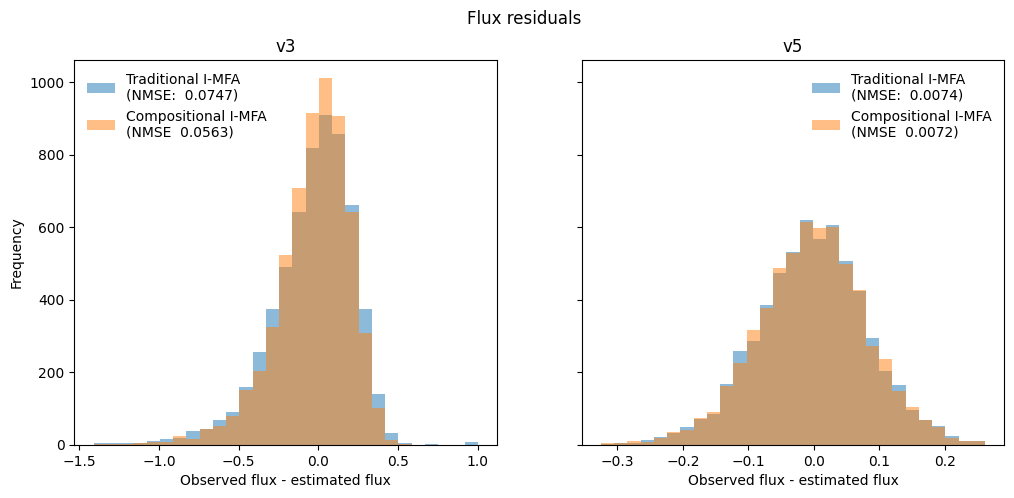

In [37]:
f, axes = plt.subplots(1, 2, figsize=[12, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_trad_i = resid_trad[:, :, i].flatten()
    resid_comp_i = resid_ilr[:, :, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(NMSE: {mse_trad[i]: .4f})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(NMSE {mse_ilr[i]: .4f})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{3+2*i}", xlabel="Observed flux - estimated flux")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");

f.suptitle("Flux residuals");
f.savefig(PLOT_DIR / "flux_residuals_toy.png", bbox_inches="tight", dpi=200)

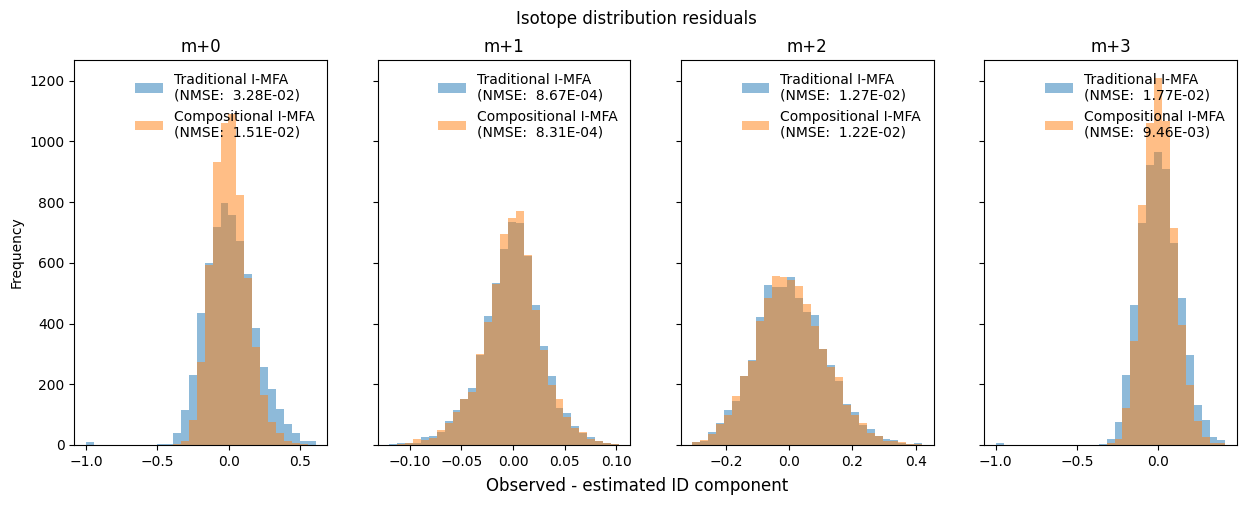

In [39]:
f, axes = plt.subplots(1, 4, figsize=[15, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_trad_i = id_resid_trad[:, :, i].flatten()
    resid_comp_i = id_resid_ilr[:, :, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(NMSE: {id_mse_trad[i]: .2E})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(NMSE: {id_mse_ilr[i]: .2E})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"m+{i}")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");
f.supxlabel("Observed - estimated ID component")

f.suptitle("Isotope distribution residuals");
f.savefig(PLOT_DIR / "ID_residuals_toy.png", bbox_inches="tight", dpi=200)

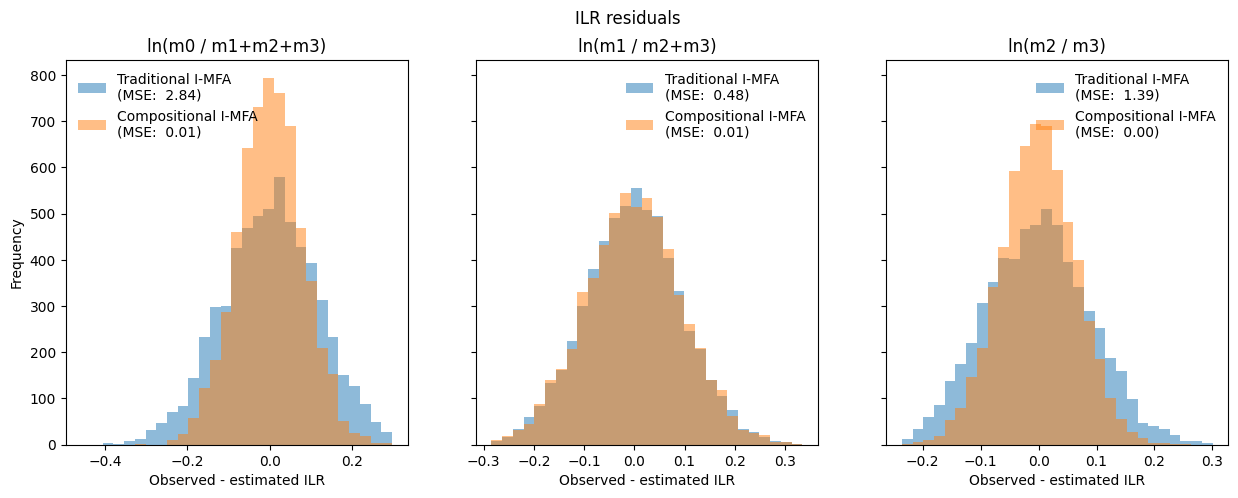

In [ ]:
ratio_lhs = (f"m{i}" for i in range(3))
ratio_rhs = ("+".join([f"m{j}" for j in range(i+1, 4)]) for i in range(3))
labels = (f"ln({ratio_lhs_i} / {ratio_rhs_i})" for ratio_lhs_i, ratio_rhs_i in zip(ratio_lhs, ratio_rhs))


f, axes = plt.subplots(1, 3, figsize=[15, 5], sharey=True)

for (i, ax), label in zip(enumerate(axes), labels):
    resid_trad_i = ilr_resid_trad[:, :, i].flatten()
    resid_comp_i = ilr_resid_ilr[:, :, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.00185)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.998)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {ilr_mse_trad[i]: .2f})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE: {ilr_mse_ilr[i]: .2f})" 
    )
    ax.set(title=label, xlabel="Observed - estimated ILR")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");
f.suptitle("ILR residuals");

**Figure caption** Traditional vs Compositional I-MFA flux estimates on a toy model. We fit traditional and compositional I-MFA to 1000 simulated datasets based on the toy model in [Antoniewicz reference]. The datasets were simulated assuming noise on pre-closure measurements with constant coefficient of variation based on a model of mass spectrometer intensity measurements (lognormal scale parameter 0.1, corresponding to approximately 2% worst error after closure to compositions).

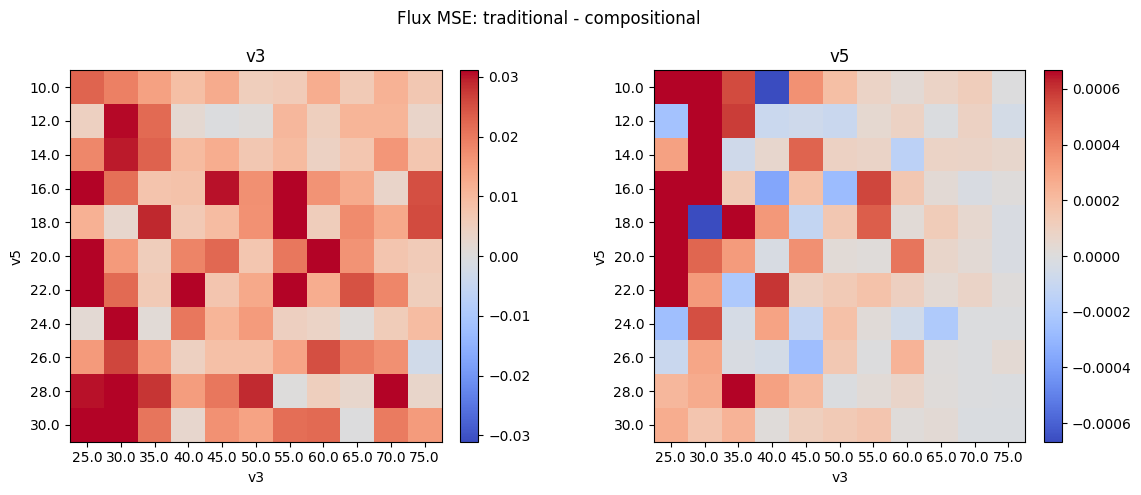

In [36]:
f, axes = plt.subplots(1, 2, figsize=[12, 5])
axes = axes.ravel()

xs = np.unique(free_fluxes[:, 0])
ys = np.unique(free_fluxes[:, 1])

diff = (resid_trad ** 2).mean(axis=1) - (resid_ilr ** 2).mean(axis=1)

for i in range(2):
    halfrange = np.quantile(np.abs(diff[:, i]), 0.9)
    norm = CenteredNorm(vcenter=0, halfrange=halfrange)
    im = axes[i].imshow(diff[:, i].reshape([11, 11]), cmap="coolwarm", norm=norm)
    f.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)
    axes[i].set_xticks(np.arange(len(xs)), xs)
    axes[i].set_yticks(np.arange(len(ys)), ys)
    axes[i].set(xlabel="v3", ylabel="v5", title=f"v{3+2*i}")
f.suptitle("Flux MSE: traditional - compositional")

f.tight_layout()

In [37]:
diff_flux = ((resid_trad ** 2).mean(axis=1) - (resid_ilr ** 2).mean(axis=1))
# /(resid_trad ** 2).mean(axis=1)
gini = jnp.column_stack((gini_indices, diff_flux))

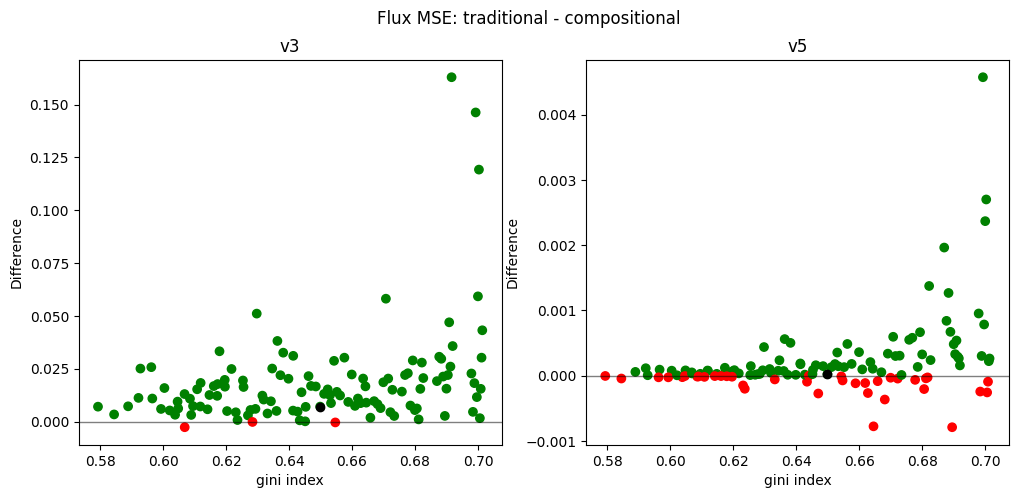

In [ ]:
f, axes = plt.subplots(1, 2, figsize=[12, 5])
axes = axes.ravel()

for i in range(2):
    y_values = gini[:, i+1]
    colors = np.where(y_values >= 0, 'green', 'red')
    axes[i].scatter(gini[:,0], y_values, c=colors)
    axes[i].scatter(gini[true_flux_index,0], y_values[true_flux_index], color="black", label="Reference flux")
    axes[i].axhline(0, color='black', lw=1, alpha=0.5)
    axes[i].set(xlabel="gini index", ylabel="Difference", title=f"v{3+2*i}")
f.suptitle("Flux NMSE: traditional - compositional")
plt.show()


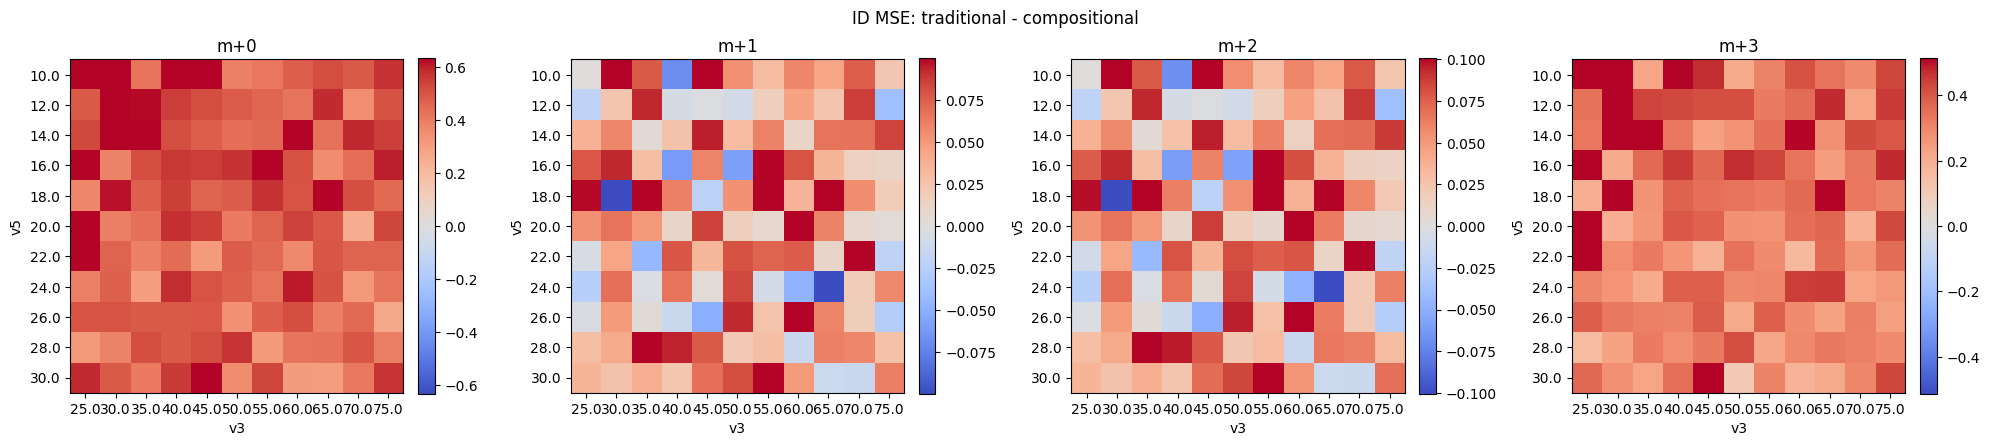

In [ ]:
f, axes = plt.subplots(1, 4, figsize=[20, 8])
axes = axes.ravel()

xs = np.unique(free_fluxes[:, 0])
ys = np.unique(free_fluxes[:, 1])

diff_id = (id_resid_trad ** 2).mean(axis=1) - (id_resid_ilr ** 2).mean(axis=1)

for i in range(4):
    halfrange = np.quantile(np.abs(diff_id[:, i]), 0.9)
    norm = CenteredNorm(vcenter=0, halfrange=halfrange)
    im = axes[i].imshow(diff_id[:, i].reshape([11, 11]), cmap="coolwarm", norm=norm)
    f.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)
    axes[i].set_xticks(np.arange(len(xs)), xs)
    axes[i].set_yticks(np.arange(len(ys)), ys)
    axes[i].set(xlabel="v3", ylabel="v5", title=f"m+{i}")
f.suptitle("ID MSE: traditional - compositional", y=0.75);
f.tight_layout()

In [40]:
diff_id = ((id_resid_trad ** 2).mean(axis=1) - (id_resid_ilr ** 2).mean(axis=1))
# /((id_resid_trad ** 2).mean(axis=1))
gini_id = jnp.column_stack((gini_indices, diff_id))

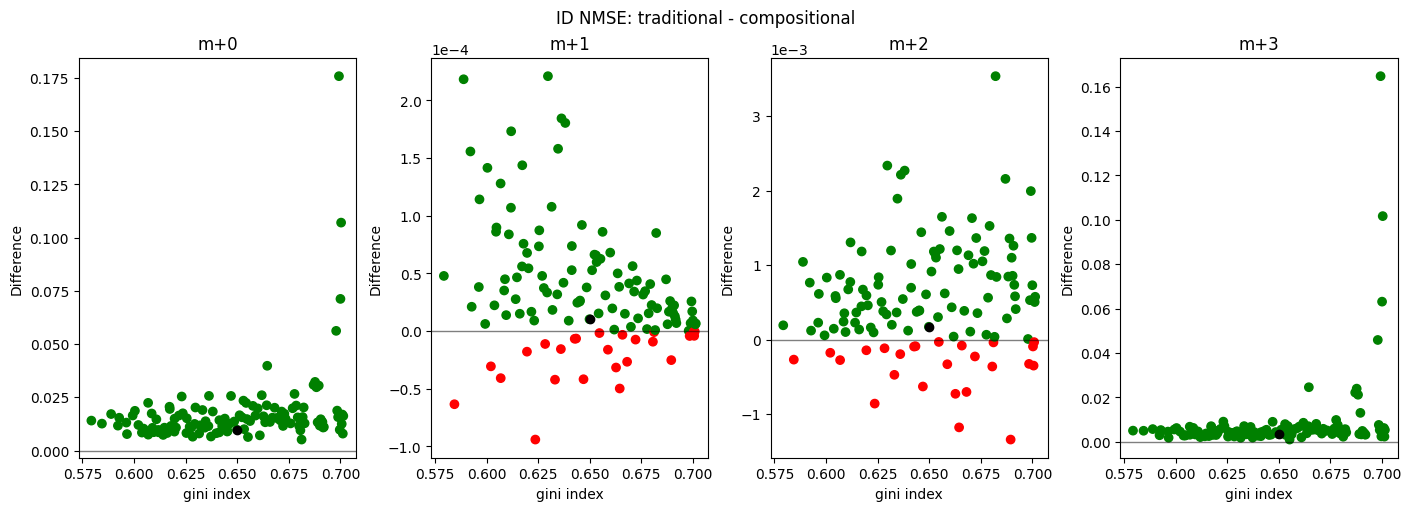

In [42]:
f, axes = plt.subplots(1, 4, figsize=[14, 5], layout="constrained")
axes = axes.ravel()

for (i, axes) in enumerate(axes):
    y_values = gini_id[:, i+1]
    colors = np.where(y_values >= 0, 'green', 'red')
    axes.scatter(gini_id[:,0], y_values, c=colors)
    axes.scatter(gini_id[true_flux_index,0], y_values[true_flux_index], color="black", label="Reference flux")
    axes.axhline(0, color='black', lw=1, alpha=0.5)
    axes.set(xlabel="gini index", ylabel="Difference", title=f"m+{i}")
    axes.ticklabel_format(scilimits=(-2,3))
f.suptitle("ID NMSE: traditional - compositional")
plt.show()

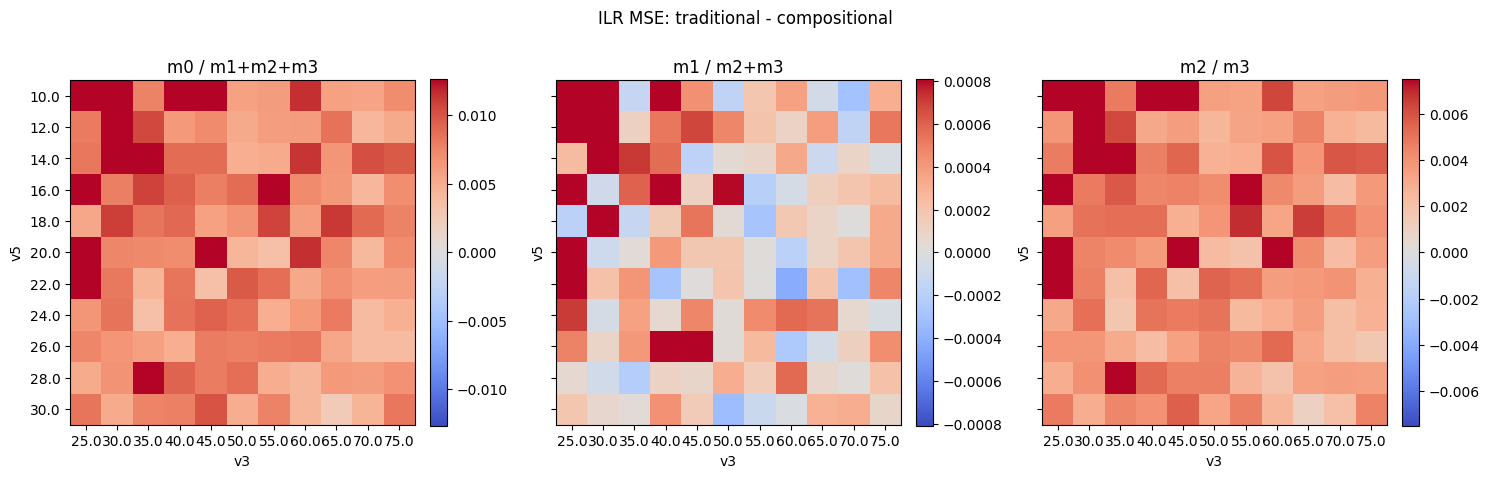

In [115]:
f, axes = plt.subplots(1, 3, sharey=True, figsize=[15, 5])

xs = np.unique(free_fluxes[:, 0])
ys = np.unique(free_fluxes[:, 1])

diff = (ilr_resid_trad ** 2).mean(axis=1) - (ilr_resid_ilr ** 2).mean(axis=1)

ratio_lhs = (f"m{i}" for i in range(3))
ratio_rhs = ("+".join([f"m{j}" for j in range(i+1, 4)]) for i in range(3))
labels = (f"{ratio_lhs_i} / {ratio_rhs_i}" for ratio_lhs_i, ratio_rhs_i in zip(ratio_lhs, ratio_rhs))


for i, label in enumerate(labels):
    halfrange = np.quantile(np.abs(diff[:, i]), 0.9)
    norm = CenteredNorm(vcenter=0, halfrange=halfrange)
    im = axes[i].imshow(diff[:, i].reshape([11, 11]), cmap="coolwarm", norm=norm)
    f.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)
    axes[i].set_xticks(np.arange(len(xs)), xs)
    axes[i].set_yticks(np.arange(len(ys)), ys)
    axes[i].set(xlabel="v3", ylabel="v5", title=label)
f.suptitle("ILR MSE: traditional - compositional", y=0.96);
f.tight_layout()

**Figure caption** Traditional vs Compositional I-MFA isotopologue estimates on a toy model. Note that compositional I-MFA is far better than traditional I-MFA at estimating ratios that are sensitive to the low-abundance isotopologues m0 and m3.